<a href="https://colab.research.google.com/github/Nasim-Amani/tag-recommender-agent-learning/blob/main/hands-on-levels/L5_LLM_tagging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Level 5: LLM tagging

**Goal:** instead of **learning** vectors from data (Levels 3–4), ask a **large language model (LLM)** to **read** each new product and choose its tags, like a person would.

**What's new compared with earlier levels:**

| | Levels 1–4 | Level 5 |
|---|---|---|
| How tags are chosen | numbers: similarity, votes, learned positions | the LLM **reads and reasons** in words |
| Training | Levels 3–4 train a model | **no training**: the LLM is used as it is |
| Input | vectors | a **prompt**: plain text |

**Link to my proposal:** this level (and Level 6) is the core of "LLM-based tag recommendation using syntactic patterns and neighboring tag attributes".

## Idea 1: the prompt

The LLM only sees **text**. Everything it needs goes into one message, the **prompt**, with three parts:

1. **Instruction:** what to do. *"Choose the 10 tags that best fit this product, most likely first. Use ONLY tags from the list."*
2. **Product text:** title + features + description of the **new** product.
3. **Allowed tags:** the full list of candidate tags (39). The LLM must choose from it, so its answer can be checked.

The LLM answers with a **ranked list** of tags.

**Why it can beat Text similarity (Level 1):** Text similarity only measures how close the words are. The LLM can **reason**: *"restores damaged, frizzy hair"* → it's for **dry hair**; *"shampoo"* → it's a **liquid**, even if the word "liquid" never appears.

**No training:** the LLM already learned language from huge amounts of text. We only **ask** it; this is called **zero-shot** use.

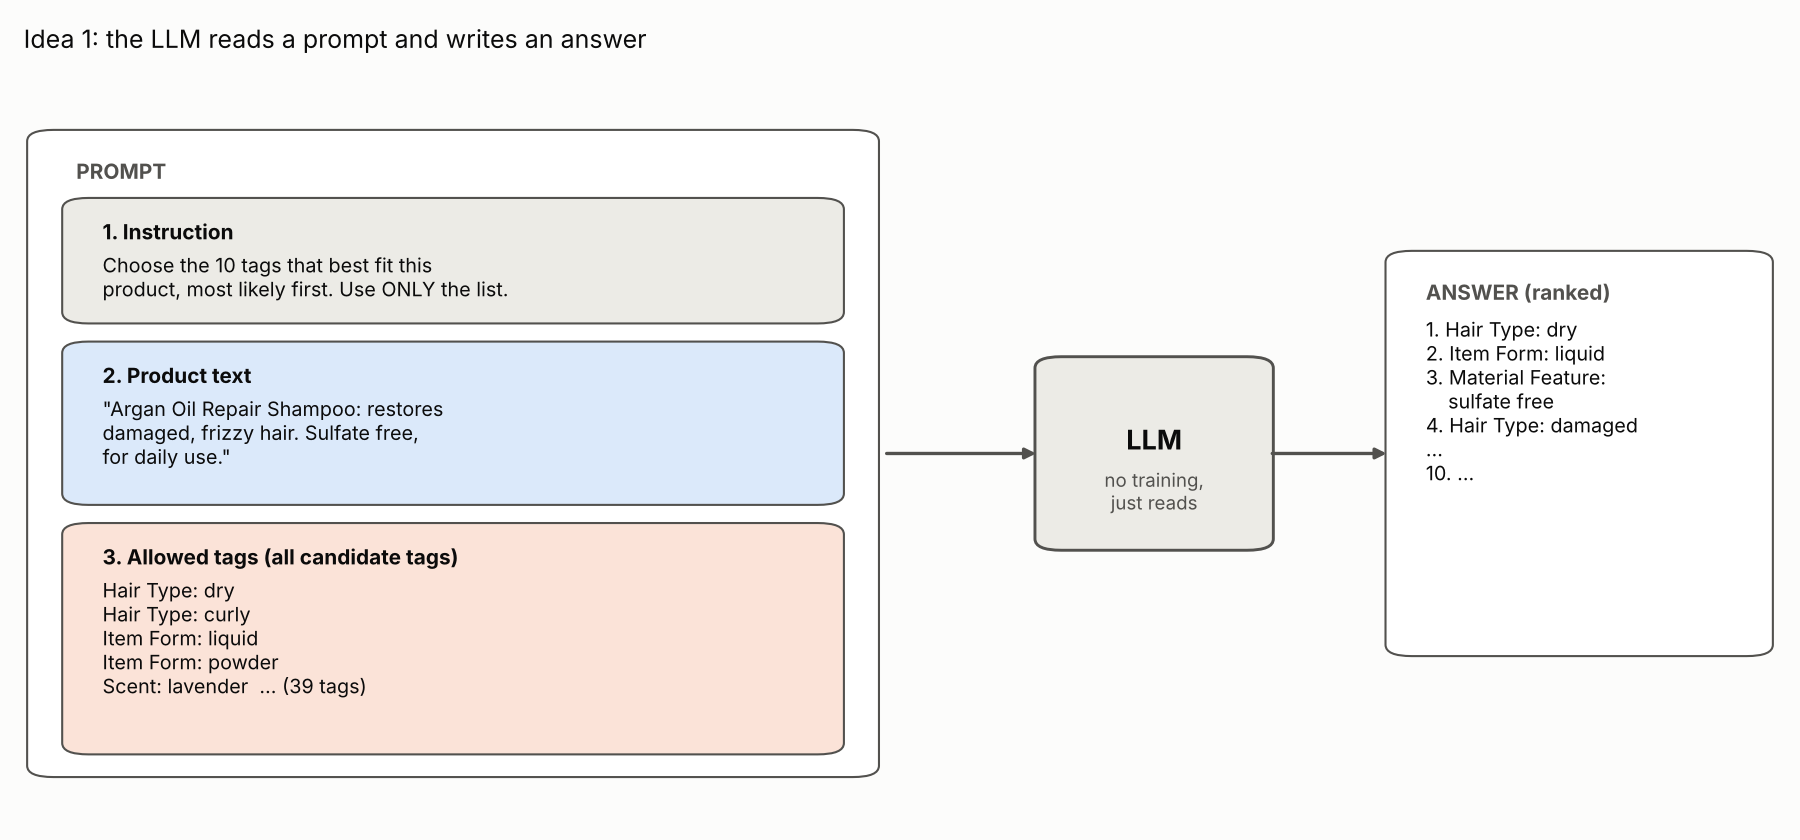

In [ ]:
#@title Figure 1: prompt -> LLM -> answer
# Safe to run: this cell re-draws the figure from the image data stored below.
from IPython.display import Image, display
import base64
display(Image(data=base64.b64decode("...")))

## Idea 2: from the answer to scores

Our `evaluate()` function needs a **score for every tag**, as in every level. So we convert the LLM's answer in two steps:

**1. Clean up.** LLMs sometimes write tags that are **not in the list** (e.g. *"Shine Boost"*), or change the spelling. Such invented answers are called **hallucinations**. We **keep only tags that exist** in the allowed list.

**2. Position → score.** `evaluate()` needs a **score** for every tag: one number saying how strongly a method believes the tag fits (higher = more likely). It uses the scores only to **sort the tags** and keep the top 10.

The LLM gives an **ordered list**, not numbers, so we turn its order into scores:

| LLM position | Score | Example (new shampoo) |
|---|---|---|
| 1 (most relevant) | 10 | `Hair Type: dry` |
| 2 | 9 | `Item Form: liquid` |
| 3 | 8 | `Hair Type: damaged` |
| … | … | … |
| 10 | 1 | … |
| **not chosen** by the LLM | **0** | `Scent: lavender`, and all other tags |

- When `evaluate()` sorts these scores, it gets back **exactly the LLM's order**. Only the order matters, not the values.
- If the LLM returns **fewer than 10** valid tags (e.g. after dropping a hallucinated one), the empty places are just tags with score 0.

Now every product has **one row of scores**, like every other level, so we use the **same metrics** (Precision, Recall, NDCG @10) and the results table stays comparable.

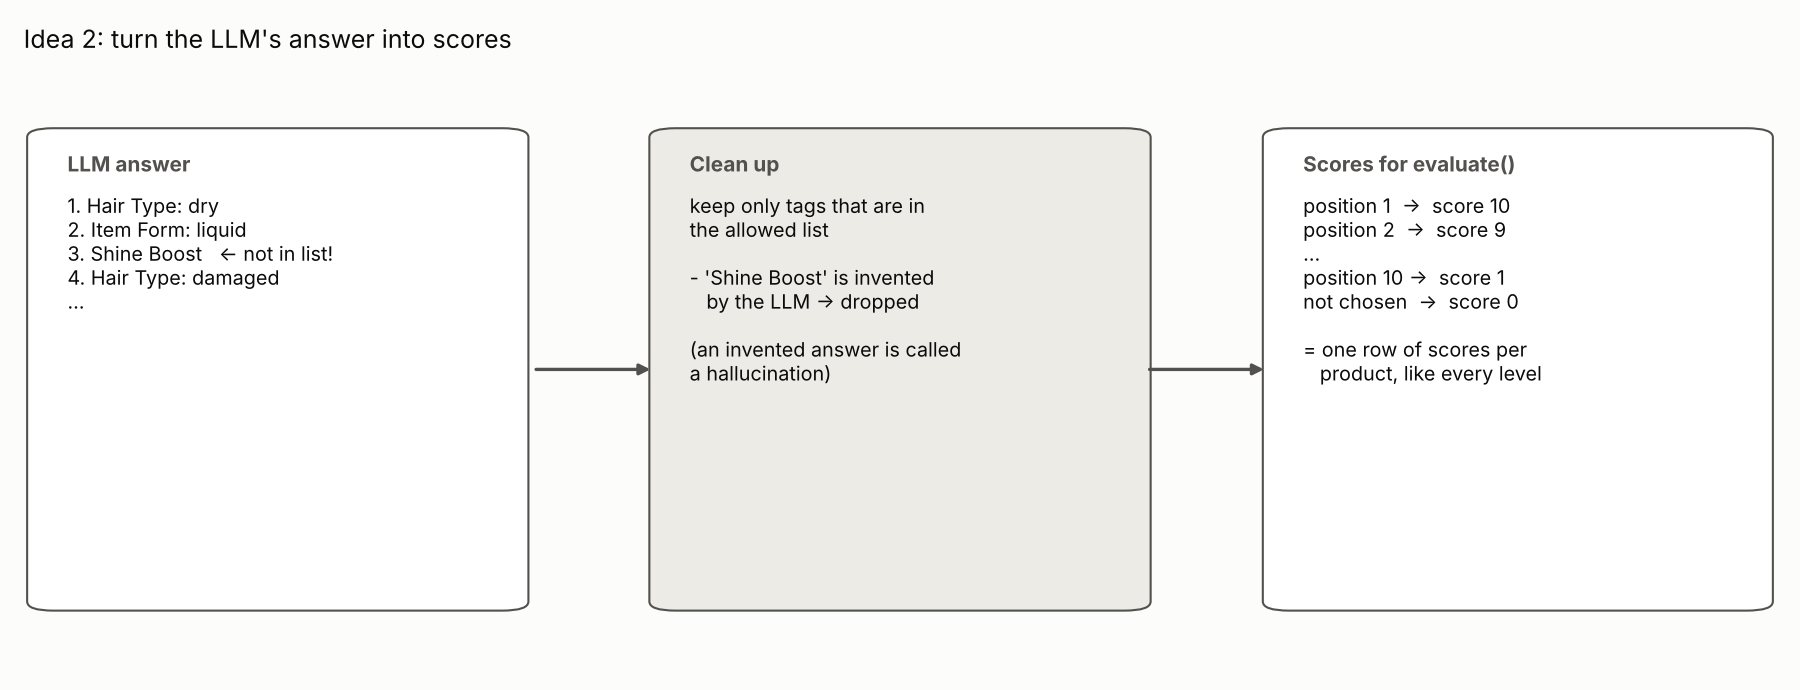

In [ ]:
#@title Figure 2: answer -> clean up -> scores
# Safe to run: this cell re-draws the figure from the image data stored below.
from IPython.display import Image, display
import base64
display(Image(data=base64.b64decode("...")))

## Idea 3: add the neighbors' tags to the prompt

**5a: LLM alone.** The prompt has only the product text. The LLM must guess everything from its own reading.

**5b: LLM + neighbors' tags.** We add one more part to the prompt: the **5 most similar training products and their true tags**, found exactly as in **Level 2** (BERT text similarity).

    Similar products and their tags:
    - Repair shampoo for damaged hair  -> Hair Type: dry, Item Form: liquid
    - Argan oil hair mask              -> Hair Type: dry, Material: argan oil
    ...

**Why this should help:**
- **Level 2** copied the neighbors' tags **blindly** (votes).
- **The LLM** sees **both** the product text **and** the neighbors' tags, so it can **choose wisely**: keep `Hair Type: dry` (fits the text), drop `Material: argan oil` if this shampoo has none.

**The name of this idea:** giving the LLM extra, retrieved information in the prompt is called **retrieval-augmented generation (RAG)**. Here the "retrieval" is simply finding the 5 similar products.

**Rule:** the neighbors are **training** products only; a new product's own tags are never shown.

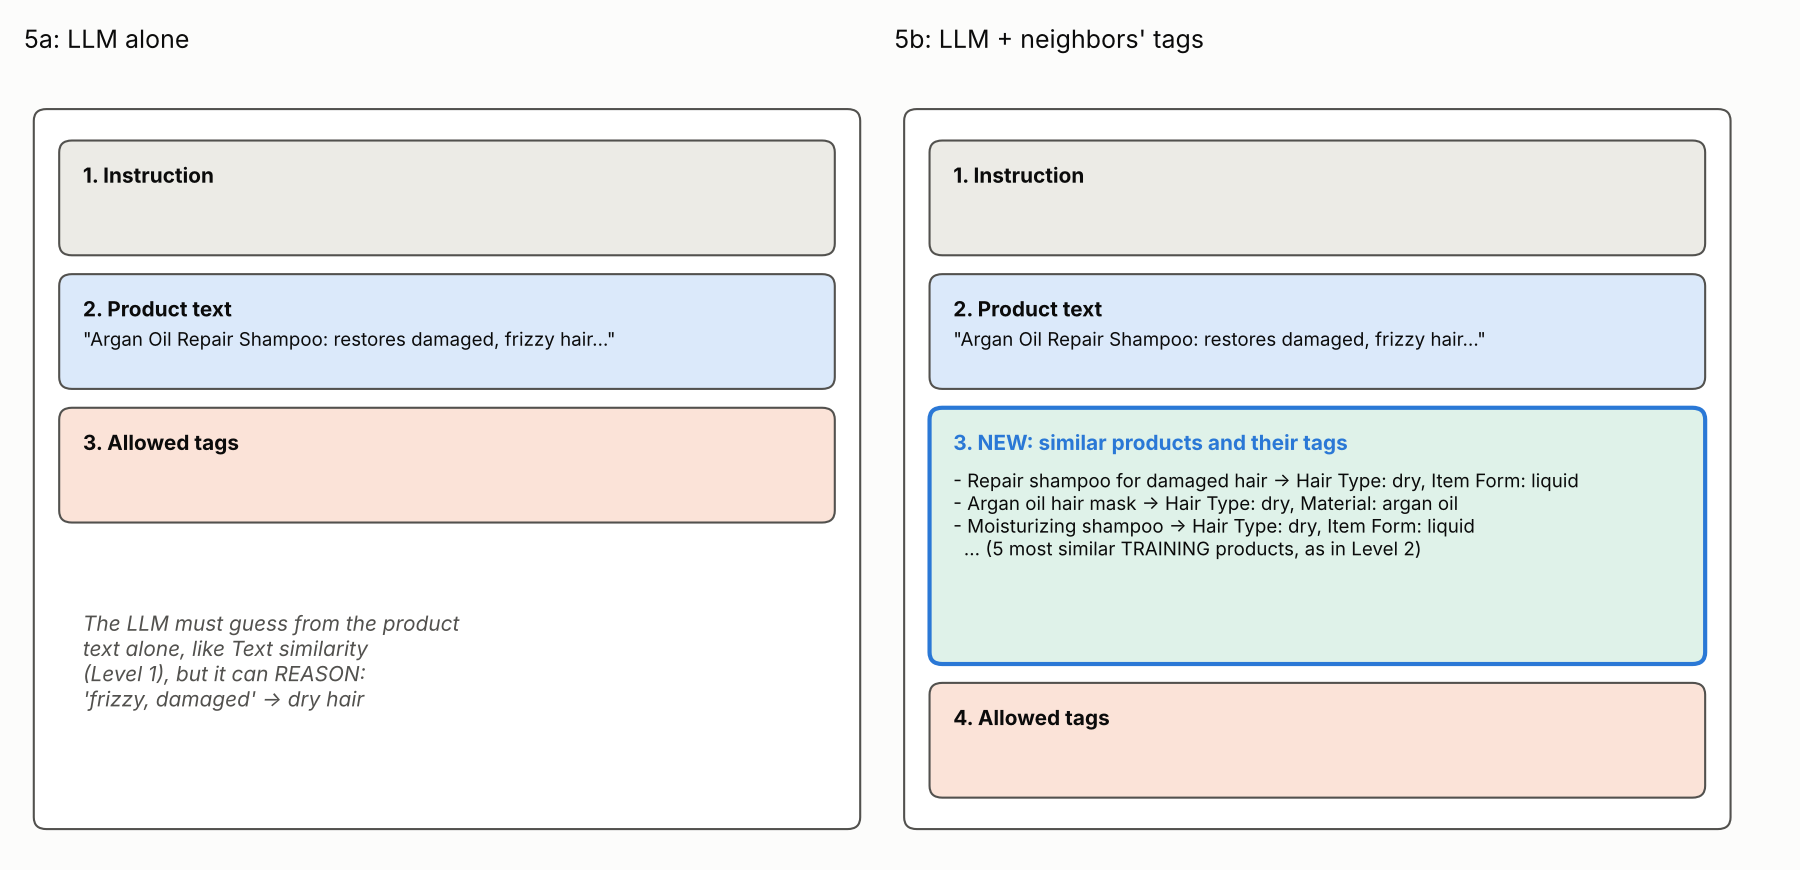

In [ ]:
#@title Figure 3: 5a vs 5b prompt
# Safe to run: this cell re-draws the figure from the image data stored below.
from IPython.display import Image, display
import base64
display(Image(data=base64.b64decode("...")))

## Idea 4: practical things that are different with LLMs

| Topic | What it means here |
|---|---|
| **One call per product** | the LLM is asked once for each test product (~160 calls), so this takes minutes, not seconds |
| **Randomness** | LLMs can give different answers each time; we set **temperature = 0** to make answers as repeatable as possible |
| **Answer format** | we ask for a fixed format (one tag per line) so the answer is easy to read in code |
| **Cost / access** | a hosted LLM needs an API key (some have free tiers); a small open model can run inside Colab on a GPU, but is weaker |

## What to expect

**5a vs Level 1 Text similarity (NDCG 0.484):** both read only the product text without training. If 5a is higher, **reasoning** beats word similarity.

**5b vs Level 2 Neighbors (0.636) and Level 3b (0.666):** if 5b is higher, combining **reading** with **neighbors' tags** beats copying votes and learned graphs.

**5b vs 5a:** shows how much the **neighbors' tags** help the LLM (expected: a lot, as in Level 2).

**Next, Level 6 (agent):** instead of **us** putting the neighbors into the prompt, the LLM **decides by itself** what information to look up (neighbors, reviews, the tag list) using **tools**.

setup, the same as Level 1 (data, tags, split)

In [ ]:
import json, gzip, os, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

# 1) Download the two files (only the first time)
base = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw"
for url, name in [(f"{base}/meta_categories/meta_All_Beauty.jsonl.gz", "meta.jsonl.gz"),
                  (f"{base}/review_categories/All_Beauty.jsonl.gz", "reviews.jsonl.gz")]:
    if not os.path.exists(name):
        urllib.request.urlretrieve(url, name)

# 2) Read the first 2,000 products
products = []
for line in gzip.open("meta.jsonl.gz", "rt"):
    products.append(json.loads(line))
    if len(products) == 2000:
        break

# 3) Reviews and first-review time of those products
reviews = {p["parent_asin"]: [] for p in products}
first_time = {}
for line in gzip.open("reviews.jsonl.gz", "rt"):
    r = json.loads(line)
    a = r["parent_asin"]
    if a in reviews:
        reviews[a].append(r["text"])
        first_time[a] = min(first_time.get(a, r["timestamp"]), r["timestamp"])

# 4) Tags = values of seller attributes, minus identifiers and junk keys
SKIP = {"Brand", "Manufacturer", "UPC", "Product Dimensions", "Item model number",
        "Date First Available", "Item Weight", "Package Dimensions",
        "Is Discontinued By Manufacturer", "Unit Count", "Number of Items",
        "Age Range (Description)", "Mounting Type", "Installation Type",
        "Package Information", "Extension Length"}

def all_tags_of(p):
    tags = []
    for key, value in p["details"].items():
        if key in SKIP or not isinstance(value, str):
            continue
        for v in value.split(","):                 # "Oily, Dry" -> two tags
            v = v.strip().lower()
            if v and v != "all":                   # "suits everyone" is not a tag
                tags.append(f"{key}: {v}")
    return tags

counts = Counter(t for p in products for t in all_tags_of(p))
candidate_tags = sorted(t for t, c in counts.items() if c >= 20)   # tags on >= 20 products
products = [p for p in products if set(all_tags_of(p)) & set(candidate_tags)]
n, m = len(products), len(candidate_tags)

# 5) Answer key Y: Y[k, j] = 1 if product k has tag j
Y = np.array([[t in all_tags_of(p) for t in candidate_tags] for p in products], dtype=float)

# 6) Split by time: oldest 70% train, next 15% validation, newest 15% test (= new products)
t = np.array([first_time.get(p["parent_asin"], np.inf) for p in products])
order = np.argsort(t)
train_idx = order[: int(0.70 * n)]
val_idx   = order[int(0.70 * n): int(0.85 * n)]
test_idx  = order[int(0.85 * n):]
print(n, "products |", m, "tags |", len(train_idx), "train /", len(val_idx), "val /", len(test_idx), "test")

1057 products | 35 tags | 739 train / 159 val / 159 test


metric, BERT vectors and the Level 1 baselines (for comparison)

In [ ]:
def evaluate(scores, products_idx, K=10):
    """scores: (products, tags), higher = more likely -> Precision@K, Recall@K, NDCG@K."""
    truth = Y[products_idx]
    top = np.argsort(-scores, axis=1)[:, :K]                    # the K best tags per product
    hits = np.take_along_axis(truth, top, axis=1)               # 1 where a recommended tag is correct
    n_true = truth.sum(axis=1)
    discount = 1 / np.log2(np.arange(2, K + 2))                 # position 1 counts most
    ideal = np.array([discount[:int(min(nt, K))].sum() for nt in n_true])
    return {"Precision@10": (hits.sum(axis=1) / K).mean(),
            "Recall@10":    (hits.sum(axis=1) / n_true).mean(),
            "NDCG@10":      ((hits * discount).sum(axis=1) / ideal).mean()}

# BERT vectors for products and tags
encoder = SentenceTransformer("all-MiniLM-L6-v2")
texts = [p["title"] + " " + " ".join(p["features"] + p["description"]) for p in products]
Z_prod = encoder.encode(texts, normalize_embeddings=True)          # (n, 384)
Z_tag  = encoder.encode(candidate_tags, normalize_embeddings=True) # (m, 384)

# Level 1 baselines
results = {}
rng = np.random.default_rng(0)
results["Random"] = evaluate(rng.random((len(test_idx), m)), test_idx)
results["Popularity"] = evaluate(np.tile(Y[train_idx].sum(axis=0), (len(test_idx), 1)), test_idx)
results["Text similarity"] = evaluate(Z_prod[test_idx] @ Z_tag.T, test_idx)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:

# ===== Level 2: borrow tags from the most similar TRAINING products =====
K_NEIGHBORS = 5

# 1) Similarity of every test product to every training product (BERT vectors from Level 1)
sims = Z_prod[test_idx] @ Z_prod[train_idx].T            # (test products, train products)

# 2) The 5 most similar training products for each test product
top = np.argsort(-sims, axis=1)[:, :K_NEIGHBORS]          # positions inside train_idx
neighbors = train_idx[top]                                # real product numbers, (test, 5)
neighbor_sims = np.take_along_axis(sims, top, axis=1)     # their similarity scores, (test, 5)

# 3a) Vote: each tag's score = number of neighbors that have it
#     Y[neighbors] is (test, 5, tags) -> sum over the 5 neighbors -> (test, tags)
votes = Y[neighbors].sum(axis=1)
results["Neighbors (vote)"] = evaluate(votes, test_idx)

# 3b) Weighted vote: closer neighbors count more (each neighbor's tags x its similarity)
weighted = (neighbor_sims[:, :, None] * Y[neighbors]).sum(axis=1)
results["Neighbors (weighted)"] = evaluate(weighted, test_idx)

table = pd.DataFrame(results).T.round(3)
table

,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636


graph builder, model and training

In [ ]:
import torch
import torch.nn.functional as F

# Use the GPU if Colab has one, otherwise the CPU (this small graph is fast on CPU too)
device = "cpu"

# ------------------------------------------------------------------
# Node numbering: one number per node in the graph
#   products = 0 .. n-1        (e.g. product 5 is node 5)
#   tags     = n .. n+m-1      (e.g. tag 0 is node n, tag 1 is node n+1, ...)
# ------------------------------------------------------------------
N_NODES = n + m


def build_graph(extra_pairs=None):
    """Build the graph's EDGES (the lines on the map). They come from the DATA, not chance.
    - product <-> tag edges: every TRAINING product with each of its true tags
    - extra_pairs (used in 3b): product <-> product edges from text similarity
    Returns the graph as a normalized 'adjacency matrix' A:
    A[i, j] > 0 means node i receives information from node j."""

    # 1) All (train product, true tag) pairs -> one edge each
    rows, cols = np.where(Y[train_idx] == 1)        # rows = position in train_idx, cols = tag number
    prod = train_idx[rows]                          # real product node numbers
    tag = n + cols                                  # tag node numbers (tags start at n)

    # 2) Edges go both ways: product -> tag AND tag -> product
    #    (so information flows in both directions during message passing)
    src, dst = [prod, tag], [tag, prod]             # src = sender, dst = receiver

    # 3) (3b only) add product <-> product edges, also both ways
    if extra_pairs is not None:
        a, b = extra_pairs
        src += [a, b]; dst += [b, a]
    src, dst = np.concatenate(src), np.concatenate(dst)

    # 4) Normalize: a node with many edges (e.g. a popular tag on 500 products) would
    #    otherwise get a huge sum of messages. Each edge's weight = 1 / sqrt(deg_sender * deg_receiver)
    deg = np.bincount(src, minlength=N_NODES).astype(float)       # number of edges per node
    w = 1 / np.sqrt(deg[src] * deg[dst])

    # 5) Store A as a SPARSE matrix: only the edges are stored, not the millions of zeros
    A = torch.sparse_coo_tensor(
        torch.tensor(np.vstack([dst, src])),        # positions: (receiver, sender)
        torch.tensor(w, dtype=torch.float32),       # values: the edge weights
        (N_NODES, N_NODES)).coalesce()
    return A.to(device)


class LightGCN(torch.nn.Module):
    """The model. Its ONLY learnable part is the start position (vector) of every node."""

    def __init__(self, n_nodes, dim=64, n_layers=3):
        super().__init__()
        # Idea 1: every node gets a vector of 64 numbers = its position on the map
        self.emb = torch.nn.Embedding(n_nodes, dim)
        torch.nn.init.normal_(self.emb.weight, std=0.1)    # random start positions
        self.n_layers = n_layers

    def forward(self, A):
        # Idea 2: message passing = each node moves toward its connections
        x = self.emb.weight                                # layer 0: the start positions
        layers = [x]
        for _ in range(self.n_layers):                     # 3 rounds of mixing
            x = torch.sparse.mm(A, x)                      # each node = weighted mix of its neighbors
            layers.append(x)
        # Final position = average of layer 0, 1, 2, 3
        # (keeps some of the node's own position + what it learned from 1, 2, 3 steps away)
        return torch.stack(layers).mean(dim=0)             # (N_NODES, 64)


def train_lightgcn(A, epochs=300, verbose=True):
    """Idea 3: adjust the start positions so each product is closer to its TRUE tags
    than to RANDOM tags (the BPR rule). Returns the final positions of all nodes."""
    torch.manual_seed(0); np.random.seed(0)                # same result every run
    model = LightGCN(N_NODES).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)   # Adam nudges the positions

    # The training examples: every (train product, true tag) pair
    rows, cols = np.where(Y[train_idx] == 1)
    pos_prod = torch.tensor(train_idx[rows], device=device)      # products
    pos_tag = torch.tensor(n + cols, device=device)              # their true tags

    for epoch in range(1, epochs + 1):
        # For each pair, pick one RANDOM tag to compare against (e.g. "nail polish")
        neg_tag = torch.randint(n, n + m, pos_tag.shape, device=device)

        E = model(A)                                             # current final positions

        # Score = dot product = how close two points are (bigger = closer)
        s_pos = (E[pos_prod] * E[pos_tag]).sum(dim=1)            # product vs TRUE tag
        s_neg = (E[pos_prod] * E[neg_tag]).sum(dim=1)            # product vs RANDOM tag

        # BPR loss: small when s_pos is much bigger than s_neg (rule respected),
        #           large when the random tag is as close as the true one (rule broken)
        loss = -F.logsigmoid(s_pos - s_neg).mean()

        # Adam: compute how to move every start position to reduce the loss, then move it
        opt.zero_grad(); loss.backward(); opt.step()

        # Every 50 epochs: check progress on VALIDATION products (not used for training)
        if verbose and epoch % 50 == 0:
            with torch.no_grad():                                # just measuring, no learning
                E = model(A)
                val = evaluate((E[val_idx] @ E[n:].T).cpu().numpy(), val_idx)["NDCG@10"]
            print(f"epoch {epoch}: loss {loss.item():.4f}, validation NDCG@10 {val:.3f}")

    # After training: the final positions of all nodes
    with torch.no_grad():
        E = model(A)
    return E


def lightgcn_scores(E, idx):
    """Score every tag for the products in idx = how close each tag is to each product.
    E[idx]: product positions (products, 64);  E[n:]: tag positions (tags, 64)
    Result: (products, tags) score table -> evaluate() keeps the top 10 per product."""
    return (E[idx] @ E[n:].T).cpu().numpy()

3a, the plain graph

In [ ]:
A_plain = build_graph()
E_plain = train_lightgcn(A_plain)
results["LightGCN (plain)"] = evaluate(lightgcn_scores(E_plain, test_idx), test_idx)
pd.DataFrame(results).T.round(3)

/tmp/ipykernel_1629/4004397956.py:43: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  A = torch.sparse_coo_tensor(


epoch 50: loss 0.1060, validation NDCG@10 0.123
epoch 100: loss 0.0882, validation NDCG@10 0.167
epoch 150: loss 0.0829, validation NDCG@10 0.157
epoch 200: loss 0.0866, validation NDCG@10 0.212
epoch 250: loss 0.0752, validation NDCG@10 0.182
epoch 300: loss 0.0739, validation NDCG@10 0.168


,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636
LightGCN (plain),0.065,0.361,0.203


3b, the graph with text neighbors

In [ ]:
# Every product -> its 5 most similar TRAINING products (never itself)
sims_all = Z_prod @ Z_prod[train_idx].T                  # (all products, train products)
sims_all[train_idx, np.arange(len(train_idx))] = -np.inf # a train product is not its own neighbor
top5 = np.argsort(-sims_all, axis=1)[:, :5]
pairs = (np.repeat(np.arange(n), 5), train_idx[top5].ravel())   # (product, neighbor) pairs

A_text = build_graph(extra_pairs=pairs)
E_text = train_lightgcn(A_text)
results["LightGCN + text neighbors"] = evaluate(lightgcn_scores(E_text, test_idx), test_idx)
pd.DataFrame(results).T.round(3)

epoch 50: loss 0.1813, validation NDCG@10 0.722
epoch 100: loss 0.1516, validation NDCG@10 0.730
epoch 150: loss 0.1477, validation NDCG@10 0.730
epoch 200: loss 0.1394, validation NDCG@10 0.736
epoch 250: loss 0.1266, validation NDCG@10 0.732
epoch 300: loss 0.1299, validation NDCG@10 0.735


,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636
LightGCN (plain),0.065,0.361,0.203
LightGCN + text neighbors,0.173,0.901,0.666


find phrases with spaCy

In [ ]:
!python -m spacy download en_core_web_sm -q
import spacy
from collections import Counter
nlp = spacy.load("en_core_web_sm", disable=["ner"])

def phrases_of(doc):
    """Adjective + noun pairs, e.g. 'frizzy hair', 'long lasting' -> {'frizzy hair', ...}"""
    return {f"{t.lemma_.lower()} {t.head.lemma_.lower()}"
            for t in doc if t.dep_ == "amod" and t.head.pos_ == "NOUN" and t.is_alpha}

# Parse the product text (title + features + description) of ALL products: new ones have text too
product_phrases = [phrases_of(doc) for doc in nlp.pipe([t[:1000] for t in texts], batch_size=64)]

# Keep phrases shared by 3..200 products: rarer ones connect nothing, more common ones are too generic
phrase_count = Counter(q for s in product_phrases for q in s)
kept_phrases = sorted(q for q, c in phrase_count.items() if 3 <= c <= 200)
print(len(phrase_count), "phrases found ->", len(kept_phrases), "kept as groups")
print("most shared:", [q for q, _ in phrase_count.most_common(10)])

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
1537 phrases found -> 38 kept as groups
most shared: ['high quality', 'synthetic fiber', 'human hair', 'costume party', 'fine line', 'damage hair', 'essential oil', 'own hair', 'full head', 'adjustable strap']


turn a list of groups into the propagation matrix

In [ ]:
import scipy.sparse as sp

def build_hypergraph(hyperedges):
    """hyperedges: list of groups, each a list of node numbers.
    Returns A = Dv^-1/2 H De^-1 H^T Dv^-1/2  (the paper's formula, with all group weights = 1),
    which plays the same role as A in Level 3: 'who talks to whom, and how strongly'."""
    # Incidence matrix H: rows = nodes, columns = groups, 1 = node is in the group
    rows = [v for e in hyperedges for v in e]
    cols = [g for g, e in enumerate(hyperedges) for _ in e]
    H = sp.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(N_NODES, len(hyperedges)))

    Dv = np.asarray(H.sum(axis=1)).ravel()                 # how many groups each node is in
    De = np.asarray(H.sum(axis=0)).ravel()                 # how many nodes each group has
    dv = np.where(Dv > 0, 1 / np.sqrt(np.maximum(Dv, 1)), 0.0)

    # nodes -> group (average: / De), then group -> nodes, normalized on both sides by Dv
    A = (sp.diags(dv) @ H @ sp.diags(1 / De) @ H.T @ sp.diags(dv)).tocoo()
    A = torch.sparse_coo_tensor(torch.tensor(np.vstack([A.row, A.col]), dtype=torch.long),
                                torch.tensor(A.data, dtype=torch.float32), (N_NODES, N_NODES)).coalesce()
    return A.to(device)

# --- The groups ---
# 1) Tag groups: tag node + all TRAIN products that have the tag
tag_groups = [[n + j] + list(train_idx[Y[train_idx, j] == 1]) for j in range(m)]

# 2) Neighbor groups: each product + its 5 most similar TRAIN products (not itself)
sims_all = Z_prod @ Z_prod[train_idx].T
sims_all[train_idx, np.arange(len(train_idx))] = -np.inf
top5 = np.argsort(-sims_all, axis=1)[:, :5]
neighbor_groups = [[k] + list(train_idx[top5[k]]) for k in range(n)]

# 3) Phrase groups: all products (old AND new) whose text contains the phrase
phrase_groups = [[k for k in range(n) if q in product_phrases[k]] for q in kept_phrases]

print(len(tag_groups), "tag groups |", len(neighbor_groups), "neighbor groups |", len(phrase_groups), "phrase groups")

35 tag groups | 1057 neighbor groups | 38 phrase groups


4a: Hypergraph with tag groups + neighbor groups


In [ ]:
A_4a = build_hypergraph(tag_groups + neighbor_groups)
E_4a = train_lightgcn(A_4a)                        # same model and training as Level 3
results["Hypergraph (tags + neighbors)"] = evaluate(lightgcn_scores(E_4a, test_idx), test_idx)
pd.DataFrame(results).T.round(3)

epoch 50: loss 0.2556, validation NDCG@10 0.688
epoch 100: loss 0.2050, validation NDCG@10 0.725
epoch 150: loss 0.1925, validation NDCG@10 0.735
epoch 200: loss 0.1832, validation NDCG@10 0.725
epoch 250: loss 0.1693, validation NDCG@10 0.722
epoch 300: loss 0.1722, validation NDCG@10 0.722


,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636
LightGCN (plain),0.065,0.361,0.203
LightGCN + text neighbors,0.173,0.901,0.666
Hypergraph (tags + neighbors),0.175,0.911,0.658


4b: + phrase groups



In [ ]:
A_4b = build_hypergraph(tag_groups + neighbor_groups + phrase_groups)
E_4b = train_lightgcn(A_4b)
results["Hypergraph + phrases"] = evaluate(lightgcn_scores(E_4b, test_idx), test_idx)
pd.DataFrame(results).T.round(3)

epoch 50: loss 0.2562, validation NDCG@10 0.682
epoch 100: loss 0.2053, validation NDCG@10 0.714
epoch 150: loss 0.1929, validation NDCG@10 0.722
epoch 200: loss 0.1837, validation NDCG@10 0.717
epoch 250: loss 0.1698, validation NDCG@10 0.710
epoch 300: loss 0.1727, validation NDCG@10 0.715


,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636
LightGCN (plain),0.065,0.361,0.203
LightGCN + text neighbors,0.173,0.901,0.666
Hypergraph (tags + neighbors),0.175,0.911,0.658
Hypergraph + phrases,0.175,0.911,0.658


connect to Groq

In [ ]:
!pip install -q groq
from google.colab import userdata, drive
from groq import Groq
import re, time, json, os

client = Groq(api_key=userdata.get("GROQ_API_KEY"))
MODEL = "openai/gpt-oss-20b"            # or "llama-3.1-8b-instant" (separate limits, faster)

# Answers are saved in Google Drive, so they survive restarts and the next day's session
drive.mount("/content/drive")
CACHE_FILE = "/content/drive/MyDrive/level5_llm_answers.json"
cache = json.load(open(CACHE_FILE)) if os.path.exists(CACHE_FILE) else {}
print("saved runs:", {name: len(v) for name, v in cache.items()})

Mounted at /content/drive
saved runs: {}


## The LLM toolkit: prompt → call → scores

This cell only **defines** the pieces; nothing is sent to the LLM yet. It has four parts:

**1. Build the prompt** (`product_text`, `make_prompt`, `INSTRUCTION`)
- `INSTRUCTION`: the rules for the LLM: choose 10 tags, most likely first, **only** from the allowed list, one per line.
- `make_prompt(k)`: the message for product `k`: **product text** + **allowed tags** (5a).
- `make_prompt(k, neighbor_ids=...)`: the same, plus the **5 most similar training products and their true tags** (5b).

**2. Call the LLM safely** (`ask_llm`, `wait_seconds`, `DailyLimitReached`)
- Sends one prompt to Groq and returns the answer text. `temperature=0` keeps answers as repeatable as possible.
- **Per-minute limit** hit → waits exactly as long as Groq says, then retries.
- **Daily limit** hit → stops (`DailyLimitReached`); the run can be continued later.

**3. Turn the answer into scores** (`tag_lookup`, `answer_to_scores`)
- **Clean up:** remove numbering and formatting (`"1. **Hair Type: dry**"` → `hair type: dry`), keep only tags that exist in the list (drops hallucinations like *"Shine Boost"*), and drop repeats.
- **Position → score:** position 1 = 10, position 2 = 9, …, position 10 = 1, not chosen = 0, so `evaluate()` can be used as in every level.

**Example (new shampoo):**

    LLM answer:  1. Hair Type: dry   2. Item Form: liquid   3. Shine Boost
    kept tags:   ['Hair Type: dry', 'Item Form: liquid']          <- 'Shine Boost' dropped
    scores:      Hair Type: dry = 10, Item Form: liquid = 9, all other tags = 0

In [ ]:
# Lookup table to match the LLM's text back to our tag list (ignoring upper/lower case)
tag_lookup = {t.lower(): j for j, t in enumerate(candidate_tags)}

In [ ]:
def product_text(k, max_chars=800):
    """Title + features + description of product k, cut to max_chars."""
    p = products[k]
    return (p["title"] + ". " + " ".join(p["features"] + p["description"]))[:max_chars]

def make_prompt(k, neighbor_ids=None):
    """Build the prompt for product k. If neighbor_ids is given (5b), add their titles and TRUE tags."""
    parts = [f"PRODUCT:\n{product_text(k)}"]
    if neighbor_ids is not None:
        lines = []
        for nb in neighbor_ids:                                   # TRAINING products only
            nb_tags = [candidate_tags[j] for j in np.where(Y[nb] == 1)[0]]
            lines.append(f"- {products[nb]['title'][:80]} -> {', '.join(nb_tags)}")
        parts.append("SIMILAR PRODUCTS AND THEIR TAGS:\n" + "\n".join(lines))
    parts.append("ALLOWED TAGS:\n" + "\n".join(candidate_tags))
    return "\n\n".join(parts)

INSTRUCTION = ("You tag beauty products. Choose the 10 tags that best fit the PRODUCT, most likely first. "
               "Use ONLY tags from ALLOWED TAGS, copied exactly. "
               "Answer with one tag per line and nothing else.")

class DailyLimitReached(Exception):
    """Raised when the free tier's DAILY limit is used up: no point retrying until it resets."""

def wait_seconds(message, default=30):
    """Read 'Please try again in 1m2.5s' from Groq's error message -> seconds to wait."""
    m = re.search(r"try again in (?:(\d+)m)?([\d.]+)s", message)
    return int(m.group(1) or 0) * 60 + float(m.group(2)) + 1 if m else default

def ask_llm(prompt, retries=4):
    """One LLM call. Per-minute limit -> wait as long as Groq says, then retry.
    Daily limit -> stop (raise DailyLimitReached). Returns None if all retries fail."""
    for attempt in range(retries):
        try:
            extra = {"reasoning_effort": "low"} if MODEL.startswith("openai/gpt-oss") else {}
            response = client.chat.completions.create(
                model=MODEL,
                messages=[{"role": "system", "content": INSTRUCTION},
                          {"role": "user", "content": prompt}],
                temperature=0, max_completion_tokens=600, **extra)
            return response.choices[0].message.content or ""
        except Exception as e:
            message = str(e)
            if "per day" in message:                     # TPD / RPD = daily limit
                raise DailyLimitReached(message[:300])
            seconds = wait_seconds(message)
            print(f"  per-minute limit, waiting {seconds:.0f}s")
            time.sleep(seconds)
    return None

def answer_to_scores(answer, K=10):
    """LLM answer -> one row of scores: position 1 = 10, position 2 = 9, ..., not chosen = 0.
    Tags not in the allowed list (hallucinations) and repeats are dropped."""
    scores = np.zeros(len(candidate_tags))
    kept = []
    for line in answer.splitlines():
        # remove numbering / bullets / markdown, e.g. "1. **Hair Type: dry**" -> "hair type: dry"
        clean = re.sub(r"^\s*(\d+[\.\)]|[-*•])\s*", "", line).strip().strip('"`*').lower()
        j = tag_lookup.get(clean)
        if j is not None and j not in kept:
            kept.append(j)
        if len(kept) == K:
            break
    for position, j in enumerate(kept):
        scores[j] = K - position
    return scores, [candidate_tags[j] for j in kept]

try it on one product first

In [ ]:
# Try the whole pipeline on ONE new product first: prompt -> LLM answer -> cleaned tags
k = test_idx[0]
prompt = make_prompt(k)
print(prompt[:1500], "\n----------")              # what the LLM actually sees

answer = ask_llm(prompt) or ""                     # "" if the call failed
print("LLM ANSWER:\n", answer, "\n----------")     # what the LLM wrote

scores, kept = answer_to_scores(answer)            # cleaned: only valid tags, in order
print("kept tags :", kept)
print("true tags :", [candidate_tags[j] for j in np.where(Y[k] == 1)[0]])

PRODUCT:
Cotton Swab Tattoo Lipstick Kit, Long Lasting Waterproof Liquid Non-Stick Lip Stain Set, Portable Lip Gloss Lip Tint 20pcs Lipstick with Collagen Lip Masks and Brushes (Multi-colored). 

ALLOWED TAGS:
Color: black
Finish Type: glossy
Finish Type: matte
Finish Type: shimmery
Hair Type: curly
Hair Type: dry
Hair Type: straight
Hair Type: wavy
Item Form: bar
Item Form: cream
Item Form: gel
Item Form: liquid
Item Form: oil
Item Form: pair
Item Form: pencil
Item Form: powder
Item Form: spray
Item Form: stick
Item Form: wrap
Material Feature: cruelty free
Material Feature: natural
Material: acrylic
Material: cotton
Material: faux mink
Material: human hair
Material: metal
Material: plastic
Material: silk
Material: synthetic
Product Benefits: hydrating
Product Benefits: long lasting
Product Benefits: moisturizing
Skin Type: dry
Skin Type: sensitive
Style: modern 
----------
LLM ANSWER:
 Item Form: liquid
Product Benefits: long lasting
Product Benefits: moisturizing
Product Benefits: h

## Running the LLM on all new products: save and resume

`run_llm(name, with_neighbors)` asks the LLM about **every test (new) product**, about 160 calls. This cell only **defines** it; the 5a and 5b cells below run it.

**What it does, step by step:**
1. **Check what's already done:** answers are saved in Google Drive under a run name (`"5a"` or `"5b"`). Products that already have an answer are **skipped**.
2. **Ask the LLM** for each remaining product: product text only (5a), or also the neighbors' tags (5b, `with_neighbors=True`).
3. **Save every answer immediately** to Drive, so a crash, restart or limit never loses work.
4. **Pause** a little between calls (`pause=2` seconds) to stay under the per-minute limit.
5. **Stop cleanly at the daily limit:** the loop ends with a message. Run the same cell again later and it **continues where it stopped**.
6. **Turn all saved answers into scores** (`answer_to_scores`) and report how many products are **still missing**.

**Why the "missing" count matters:** a product with no answer gets **no tags**, which would make the method look worse than it is. So the 5a and 5b cells add a row to the results table **only when nothing is missing**.

**Example run:**

    5b: 159 products left to ask
      0/159 done
      20/159 done
      ...
    STOPPED: daily limit reached. Run this cell again later to continue.
    5b: 97 answered, 62 still missing        <- run again later: only the 62 are asked

In [ ]:
def run_llm(name, with_neighbors, pause=2):
    """Ask the LLM for every test product, saving each answer immediately.
    Already-saved products are skipped, so rerunning this cell RESUMES instead of starting over."""
    saved = cache.setdefault(name, {})
    todo = [row for row, k in enumerate(test_idx) if str(k) not in saved]
    print(f"{name}: {len(todo)} products left to ask")
    for i, row in enumerate(todo):
        k = test_idx[row]
        nb = neighbors[row] if with_neighbors else None
        try:
            answer = ask_llm(make_prompt(k, neighbor_ids=nb))
        except DailyLimitReached as e:
            print("STOPPED: daily limit reached. Run this cell again later to continue.\n", str(e)[:200])
            break
        if answer is None:                       # failed after retries: leave it for the next run
            continue
        saved[str(k)] = answer
        json.dump(cache, open(CACHE_FILE, "w"))  # save after EVERY answer
        if i % 20 == 0:
            print(f"  {i}/{len(todo)} done")
        time.sleep(pause)                        # steady pace keeps you under the per-minute limit

    # Scores from the saved answers (only products that have an answer)
    scores = np.zeros((len(test_idx), len(candidate_tags)))
    for row, k in enumerate(test_idx):
        scores[row], _ = answer_to_scores(saved.get(str(k), ""))
    missing = len(test_idx) - len(saved)
    print(f"{name}: {len(saved)} answered, {missing} still missing")
    return scores, missing

## 5a: LLM alone

**Goal:** see how well the LLM tags **new products** using **only their text**: no neighbors, no training.

**What the LLM sees** (for each of the ~160 test products):

    INSTRUCTION:   choose the 10 best tags, most likely first, only from the list
    PRODUCT:       "Argan Oil Repair Shampoo: restores damaged, frizzy hair..."
    ALLOWED TAGS:  Hair Type: dry, Hair Type: curly, Item Form: liquid, ... (all candidate tags)

**What happens:**
1. `run_llm("5a", with_neighbors=False)` asks the LLM once per product and **saves** every answer to Drive.
2. Each answer is cleaned and turned into **scores** (position 1 = 10 … not chosen = 0).
3. If **no product is missing**, `evaluate()` adds the row **"LLM alone (5a)"** to the results table.

**Time:** about 160 calls with short pauses, so roughly **5–10 minutes**. If it stops at the daily limit, run this cell again later; it continues where it stopped.

**Compare with:** **Text similarity** (Level 1, NDCG 0.484), which also reads only the product text, without reasoning.

In [ ]:
# 5a: LLM alone
scores_5a, missing_5a = run_llm("5a", with_neighbors=False)
if missing_5a == 0:
    results["LLM alone (5a)"] = evaluate(scores_5a, test_idx)
pd.DataFrame(results).T.round(3)

5a: 0 products left to ask
5a: 159 answered, 0 still missing


,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636
LightGCN (plain),0.065,0.361,0.203
LightGCN + text neighbors,0.173,0.901,0.666
Hypergraph (tags + neighbors),0.175,0.911,0.658
Hypergraph + phrases,0.175,0.911,0.658
LLM alone (5a),0.147,0.760,0.582


## 5b: LLM + neighbors' tags

**Goal:** see whether the LLM tags new products **better** when it also sees **what similar products are tagged**.

**What changes from 5a:** one extra part in the prompt: the **5 most similar training products and their true tags**, the same neighbors as **Level 2**.

    INSTRUCTION:   choose the 10 best tags, most likely first, only from the list
    PRODUCT:       "Argan Oil Repair Shampoo: restores damaged, frizzy hair..."
    SIMILAR PRODUCTS AND THEIR TAGS:                                   <- NEW in 5b
      - Repair shampoo for damaged hair -> Hair Type: dry, Item Form: liquid
      - Argan oil hair mask             -> Hair Type: dry, Material: argan oil
      ...
    ALLOWED TAGS:  Hair Type: dry, Hair Type: curly, Item Form: liquid, ...

**Why it should help:** Level 2 copied the neighbors' tags **blindly**. The LLM sees **both** the product text **and** the neighbors' tags, so it can **choose**: keep `Hair Type: dry` (fits the text), skip `Material: argan oil` if this shampoo doesn't fit it.

**What happens:** `run_llm("5b", with_neighbors=True)` works exactly like 5a (save, resume, score); if no product is missing, it adds the row **"LLM + neighbors (5b)"**.

**Rule:** the neighbors are **training** products only; a new product's own tags are never shown.

**Compare with:**
- **5a:** how much the neighbors' tags help the LLM
- **Level 2 Neighbors (NDCG 0.636)** and **Level 3b (0.666):** does reading + neighbors beat copying votes or a learned graph?

In [ ]:
# 5b: LLM + neighbors' tags
scores_5b, missing_5b = run_llm("5b", with_neighbors=True)
if missing_5b == 0:
    results["LLM + neighbors (5b)"] = evaluate(scores_5b, test_idx)
pd.DataFrame(results).T.round(3)

5b: 159 products left to ask
  0/159 done
  20/159 done
STOPPED: daily limit reached. Run this cell again later to continue.
 Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-20b` in organization `org_01m4jkr9y7e5sb2h48g56a1f16` service tier `on_demand` on tokens per day (TPD): Limit 2000
5b: 23 answered, 136 still missing


,Precision@10,Recall@10,NDCG@10
Random,0.048,0.241,0.133
Popularity,0.116,0.573,0.340
Text similarity,0.123,0.651,0.484
Neighbors (vote),0.148,0.765,0.630
Neighbors (weighted),0.148,0.765,0.636
LightGCN (plain),0.065,0.361,0.203
LightGCN + text neighbors,0.173,0.901,0.666
Hypergraph (tags + neighbors),0.175,0.911,0.658
Hypergraph + phrases,0.175,0.911,0.658
LLM alone (5a),0.147,0.760,0.582
